In [4]:
import os
os.chdir("/home/jupyter/fire-impact-curves/notebooks")
print(os.getcwd())

import sys
sys.path.append("/home/jupyter/fire-impact-curves")

/home/jupyter/fire-impact-curves/notebooks


In [5]:
import geopandas as gpd
import pandas as pd
from src.fires import load_fire

full = pd.read_parquet("../data/processed/all_cells_current.parquet")
all_uids = full["uid"].unique()

fire_geoms = []
for uid in all_uids:
    fire = load_fire(uid)
    fire_geoms.append({"project_id": uid, "geometry": fire.geometry.iloc[0]})

projects = gpd.GeoDataFrame(fire_geoms, crs=fire.crs)
projects.to_file("../data/processed/fire_aois.shp")
print(f"{len(projects)} fire AOIs saved to ../data/processed/fire_aois.shp")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

247 fire AOIs saved to ../data/processed/fire_aois.shp


In [7]:
import subprocess, os

os.makedirs("../data/sentinel2_grid", exist_ok=True)
base = "https://raw.githubusercontent.com/justinelliotmeyers/Sentinel-2-Shapefile-Index/master/sentinel_2_index_shapefile"

for ext in ["shp", "shx", "dbf", "prj"]:
    subprocess.run([
        "wget", "-c", "-O", f"../data/sentinel2_grid/s2_tiles.{ext}",
        f"{base}.{ext}"
    ], check=True)

print(os.listdir("../data/sentinel2_grid"))
for f in os.listdir("../data/sentinel2_grid"):
    print(f, os.path.getsize(f"../data/sentinel2_grid/{f}"), "bytes")


--2026-11-03 11:40:38--  https://raw.githubusercontent.com/justinelliotmeyers/Sentinel-2-Shapefile-Index/master/sentinel_2_index_shapefile.shp
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14132132 (13M) [application/octet-stream]
Saving to: ‘../data/sentinel2_grid/s2_tiles.shp’

     0K .......... .......... .......... .......... ..........  0% 45.9M 0s
    50K .......... .......... .......... .......... ..........  0% 42.5M 0s
   100K .......... .......... .......... .......... ..........  1% 58.9M 0s
   150K .......... .......... .......... .......... ..........  1%  119M 0s
   200K .......... .......... .......... .......... ..........  1%  119M 0s
   250K .......... .......... .......... .......... ..........  2% 83.7M 0s
   300K .......... ..........

['s2_tiles.zip', 's2_tiles.shp', 's2_tiles.kml', 's2_tiles.dbf', 's2_tiles.shx', 's2_tiles.prj']
s2_tiles.zip 0 bytes
s2_tiles.shp 14132132 bytes
s2_tiles.kml 0 bytes
s2_tiles.dbf 14530986 bytes
s2_tiles.shx 455972 bytes
s2_tiles.prj 145 bytes


200 OK
Length: 145 [text/plain]
Saving to: ‘../data/sentinel2_grid/s2_tiles.prj’

     0K                                                       100% 8.05M=0s

2026-11-03 11:40:40 (8.05 MB/s) - ‘../data/sentinel2_grid/s2_tiles.prj’ saved [145/145]



In [8]:
import geopandas as gpd

s2_grid = gpd.read_file("../data/sentinel2_grid/s2_tiles.shp")
print(len(s2_grid), "tiles loaded")
print(s2_grid.columns.tolist())
print(s2_grid.head())


56984 tiles loaded
['Name', 'geometry']
    Name                                           geometry
0  01CCV  POLYGON Z ((180 -73.05974 0, 176.86462 -72.991...
1  01CCV  POLYGON Z ((-180 -72.07333 0, -179.62744 -72.0...
2  01CDH  POLYGON Z ((180 -83.80855 0, 174.71288 -83.771...
3  01CDH  POLYGON Z ((-180 -82.8259 0, -176.29744 -82.85...
4  01CDJ  POLYGON Z ((180 -82.91344 0, 175.74819 -82.883...


In [9]:
import geopandas as gpd

projects = gpd.read_file("../data/processed/fire_aois.shp")
s2_grid = gpd.read_file("../data/sentinel2_grid/s2_tiles.shp")
s2_grid = s2_grid.to_crs(projects.crs)

overlap = gpd.sjoin(projects, s2_grid, how="inner", predicate="intersects")

per_project_tiles = overlap.groupby("project_id")["Name"].apply(set)

sum_if_separate = per_project_tiles.apply(len).sum()
unique_overall = len(set.union(*per_project_tiles))

print(f"{len(per_project_tiles)} fires matched to tiles")
print(f"if every fire ran separately: {sum_if_separate} total tile-jobs")
print(f"if shared tiles were only processed once: {unique_overall} unique tiles")
print(f"potential saving from clustering: {sum_if_separate - unique_overall} tile-jobs "
      f"({(1 - unique_overall / sum_if_separate):.0%} reduction)")

tiles_per_fire = per_project_tiles.apply(len)
print(f"\ntiles per fire: min={tiles_per_fire.min()}, median={tiles_per_fire.median()}, max={tiles_per_fire.max()}")


247 fires matched to tiles
if every fire ran separately: 418 total tile-jobs
if shared tiles were only processed once: 287 unique tiles
potential saving from clustering: 131 tile-jobs (31% reduction)

tiles per fire: min=1, median=2.0, max=5


In [10]:
parent = {}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(x, y):
    rx, ry = find(x), find(y)
    if rx != ry:
        parent[rx] = ry

for pid, tiles in per_project_tiles.items():
    fire_node = ("fire", pid)
    parent.setdefault(fire_node, fire_node)
    for t in tiles:
        tile_node = ("tile", t)
        parent.setdefault(tile_node, tile_node)
        union(fire_node, tile_node)

from collections import defaultdict
groups = defaultdict(list)
for node in parent:
    groups[find(node)].append(node)

fire_counts = sorted([sum(1 for n in g if n[0] == "fire") for g in groups.values()], reverse=True)

print(f"{len(groups)} independent job clusters needed (the real job count, not tile count)")
print(f"fires per cluster: largest={fire_counts[0]}, median={fire_counts[len(fire_counts)//2]}, "
      f"single-fire clusters (no sharing possible)={sum(1 for c in fire_counts if c == 1)}")


153 independent job clusters needed (the real job count, not tile count)
fires per cluster: largest=15, median=1, single-fire clusters (no sharing possible)=110


In [11]:
fire_types = full.groupby("uid")["forest_type_label"].agg(lambda x: x.value_counts().idxmax())

pilot_fires = []
for ftype, grp in fire_types.groupby(fire_types):
    pilot_fires.extend(grp.index[:3])  # up to 3 fires per dominant forest type

print(f"{len(pilot_fires)} fires selected for the compromise pilot, by forest type:")
print(fire_types.loc[pilot_fires].value_counts())

pilot_tiles = {pid: per_project_tiles[pid] for pid in pilot_fires if pid in per_project_tiles}
pilot_unique = len(set.union(*pilot_tiles.values()))
pilot_sum = sum(len(t) for t in pilot_tiles.values())
print(f"\npilot: {len(pilot_tiles)} fires, {pilot_sum} tile-equivalents unclustered, "
      f"{pilot_unique} unique tiles")


18 fires selected for the compromise pilot, by forest type:
forest_type_label
deciduous_broadleaf     3
evergreen_broadleaf     3
evergreen_needleleaf    3
mixed                   3
not_forest              3
unknown                 3
Name: count, dtype: int64

pilot: 18 fires, 38 tile-equivalents unclustered, 32 unique tiles


In [12]:
import geopandas as gpd

sel_full = pd.read_parquet("../data/processed/forest_fires_2020_2021_attrs.parquet")
candidates = sel_full[
    (sel_full["landcover"].isin([
        "Evergreen Broadleaf forest", "Deciduous Broadleaf forest",
        "Evergreen Needleleaf forest", "Deciduous Needleleaf forest", "Mixed forest",
    ]))
    & (sel_full["size"] >= 20)
]
dupe_uids = sel_full["uid"][sel_full["uid"].duplicated(keep=False)].unique()
candidates = candidates[~candidates["uid"].isin(dupe_uids)]
print(f"{len(candidates)} candidate fires after basic filtering")

# load geometries efficiently, once per Fire Atlas file-year, not one fire at a time
candidate_geoms = []
for file_year, grp in candidates.groupby(candidates["uid"].str.split("_").str[0]):
    path = f"../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_{file_year}.shp"
    fire_ids = grp["uid"].str.split("_", n=1).str[1].tolist()
    year_shapes = gpd.read_file(path, engine="pyogrio", where=f"fire_ID IN ({','.join(fire_ids)})")
    year_shapes["uid"] = file_year + "_" + year_shapes["fire_ID"].astype(str)
    candidate_geoms.append(year_shapes[["uid", "geometry"]])

candidate_gdf = gpd.GeoDataFrame(pd.concat(candidate_geoms, ignore_index=True), crs=year_shapes.crs)
print(f"{len(candidate_gdf)} geometries loaded")


3746 candidate fires after basic filtering


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


3766 geometries loaded


In [13]:
s2_grid_c = s2_grid.to_crs(candidate_gdf.crs)
overlap_c = gpd.sjoin(candidate_gdf, s2_grid_c, how="inner", predicate="intersects")
candidate_tiles = overlap_c.groupby("uid")["Name"].apply(set)

parent = {}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(x, y):
    rx, ry = find(x), find(y)
    if rx != ry:
        parent[rx] = ry

for pid, tiles in candidate_tiles.items():
    fnode = ("fire", pid)
    parent.setdefault(fnode, fnode)
    for t in tiles:
        tnode = ("tile", t)
        parent.setdefault(tnode, tnode)
        union(fnode, tnode)

from collections import defaultdict
groups = defaultdict(list)
for node in parent:
    groups[find(node)].append(node)

multi_fire_clusters = sorted(
    [[n[1] for n in g if n[0] == "fire"] for g in groups.values() if sum(1 for n in g if n[0] == "fire") >= 2],
    key=len, reverse=True,
)
print(f"{len(multi_fire_clusters)} naturally tile-sharing clusters found among {len(candidate_tiles)} candidates")
print("top 10 cluster sizes:", [len(c) for c in multi_fire_clusters[:10]])


170 naturally tile-sharing clusters found among 3746 candidates
top 10 cluster sizes: [442, 414, 348, 329, 310, 116, 104, 98, 92, 86]


In [14]:
MAX_TILES_PER_CLUSTER = 5

clusters = []
for pid, tiles in candidate_tiles.items():
    placed = False
    for c in clusters:
        if len(c["tiles"] | tiles) <= MAX_TILES_PER_CLUSTER:
            c["fires"].append(pid)
            c["tiles"] |= tiles
            placed = True
            break
    if not placed:
        clusters.append({"fires": [pid], "tiles": set(tiles)})

print(f"{len(clusters)} jobs needed, capped at {MAX_TILES_PER_CLUSTER} tiles per job")
sizes = sorted([len(c["fires"]) for c in clusters], reverse=True)
print("fires per job, top 10:", sizes[:10])
print("single-fire jobs:", sum(1 for s in sizes if s == 1))


266 jobs needed, capped at 5 tiles per job
fires per job, top 10: [112, 110, 95, 80, 79, 78, 71, 66, 66, 65]
single-fire jobs: 3


In [15]:
clusters_sorted = sorted(clusters, key=lambda c: len(c["fires"]), reverse=True)

for i, c in enumerate(clusters_sorted[:10]):
    sub = candidates[candidates["uid"].isin(c["fires"])]
    print(f"cluster {i}: {len(c['fires'])} fires, tiles={len(c['tiles'])}")
    print("  landcover:", sub["landcover"].value_counts().to_dict())
    print("  GFED region:", sub["GFED_regio"].value_counts().to_dict())


cluster 0: 112 fires, tiles=5
  landcover: {'Mixed forest': 73, 'Deciduous Broadleaf forest': 39}
  GFED region: {8: 112}
cluster 1: 110 fires, tiles=5
  landcover: {'Deciduous Broadleaf forest': 97, 'Evergreen Broadleaf forest': 9, 'Mixed forest': 4}
  GFED region: {9: 101, 5: 9}
cluster 2: 95 fires, tiles=5
  landcover: {'Deciduous Broadleaf forest': 95}
  GFED region: {9: 95}
cluster 3: 80 fires, tiles=5
  landcover: {'Mixed forest': 79, 'Deciduous Broadleaf forest': 1}
  GFED region: {9: 80}
cluster 4: 79 fires, tiles=5
  landcover: {'Mixed forest': 66, 'Deciduous Broadleaf forest': 13}
  GFED region: {9: 79}
cluster 5: 78 fires, tiles=5
  landcover: {'Deciduous Broadleaf forest': 56, 'Mixed forest': 22}
  GFED region: {9: 78}
cluster 6: 71 fires, tiles=5
  landcover: {'Deciduous Broadleaf forest': 71}
  GFED region: {12: 71}
cluster 7: 66 fires, tiles=5
  landcover: {'Mixed forest': 56, 'Deciduous Broadleaf forest': 10}
  GFED region: {8: 66}
cluster 8: 66 fires, tiles=5
  landcov

In [16]:
cluster_info = []
for c in clusters_sorted:
    sub = candidates[candidates["uid"].isin(c["fires"])]
    combos = set(zip(sub["landcover"], sub["GFED_regio"]))
    cluster_info.append({"fires": c["fires"], "tiles": c["tiles"], "combos": combos, "n": len(c["fires"])})

covered = set()
selected = []
for c in sorted(cluster_info, key=lambda c: -c["n"]):
    new_combos = c["combos"] - covered
    if new_combos:
        selected.append(c)
        covered |= c["combos"]

total_fires = sum(c["n"] for c in selected)
print(f"{len(selected)} jobs selected, covering {len(covered)} distinct (forest type, region) combinations")
print(f"{total_fires} total fires included")
for i, c in enumerate(selected):
    sub = candidates[candidates["uid"].isin(c["fires"])]
    print(f"job {i}: {c['n']} fires, new combos added: {len(c['combos'] - (covered - c['combos']))}")
    print("  ", sub["landcover"].value_counts().to_dict(), sub["GFED_regio"].value_counts().to_dict())


25 jobs selected, covering 36 distinct (forest type, region) combinations
612 total fires included
job 0: 112 fires, new combos added: 2
   {'Mixed forest': 73, 'Deciduous Broadleaf forest': 39} {8: 112}
job 1: 110 fires, new combos added: 3
   {'Deciduous Broadleaf forest': 97, 'Evergreen Broadleaf forest': 9, 'Mixed forest': 4} {9: 101, 5: 9}
job 2: 71 fires, new combos added: 1
   {'Deciduous Broadleaf forest': 71} {12: 71}
job 3: 65 fires, new combos added: 4
   {'Deciduous Broadleaf forest': 32, 'Mixed forest': 28, 'Evergreen Broadleaf forest': 5} {9: 64, 8: 1}
job 4: 61 fires, new combos added: 3
   {'Deciduous Broadleaf forest': 53, 'Evergreen Broadleaf forest': 4, 'Mixed forest': 4} {12: 61}
job 5: 30 fires, new combos added: 2
   {'Evergreen Broadleaf forest': 22, 'Deciduous Broadleaf forest': 8} {5: 30}
job 6: 19 fires, new combos added: 4
   {'Deciduous Broadleaf forest': 18, 'Mixed forest': 1} {12: 16, 5: 2, 10: 1}
job 7: 19 fires, new combos added: 3
   {'Deciduous Broadle

In [17]:
total_tiles_selected = sum(len(c["tiles"]) for c in selected)
print(f"total tiles across all 25 jobs: {total_tiles_selected}")
print(f"estimated compute: ~{total_tiles_selected * 15} minutes (~{total_tiles_selected * 15 / 60:.1f} hours) "
      f"if run one at a time, much less with parallelism")


total tiles across all 25 jobs: 124
estimated compute: ~1860 minutes (~31.0 hours) if run one at a time, much less with parallelism


Copying gs://artio-projects/project-assessment/2020_112/biomass/2019/Q3_18693569-4.tif...
/ [1 files][ 35.6 MiB/ 35.6 MiB]                                                
Operation completed over 1 objects/35.6 MiB.                                     
Copying gs://artio-projects/project-assessment/2020_112/biomass/2019/Q3_18693595-3.tif...
/ [1 files][ 35.6 MiB/ 35.6 MiB]                                                
Operation completed over 1 objects/35.6 MiB.                                     


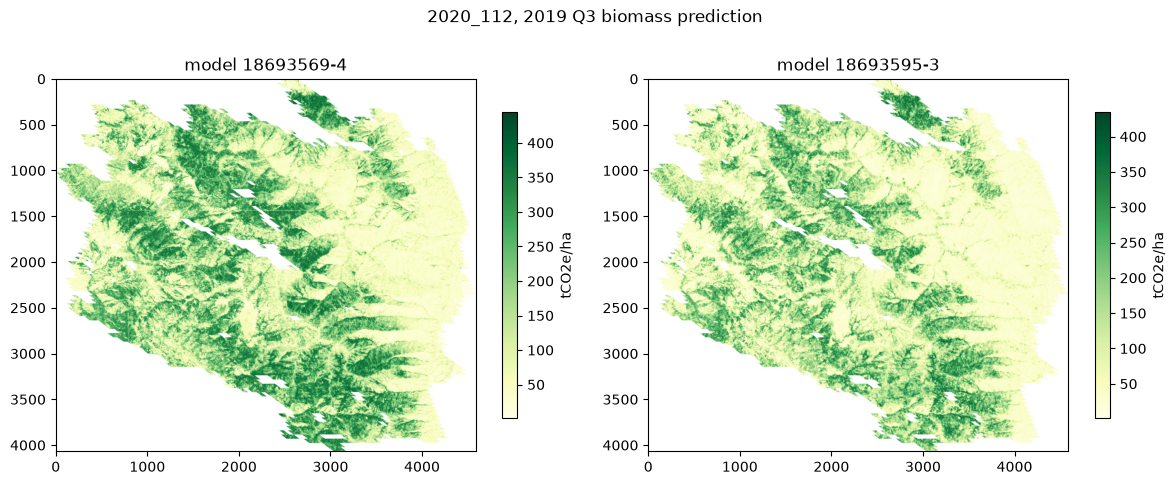

18693569-4: mean=152.4, min=1.0, max=445.0, zero_frac=0.00%
18693595-3: mean=118.0, min=1.0, max=435.0, zero_frac=0.00%


In [18]:
import subprocess
import rasterio
import numpy as np
import matplotlib.pyplot as plt

paths = {
    "18693569-4": "../data/artio_test/2020_112_2019Q3_18693569-4.tif",
    "18693595-3": "../data/artio_test/2020_112_2019Q3_18693595-3.tif",
}

for model_id, local_path in paths.items():
    subprocess.run([
        "gsutil", "cp",
        f"gs://artio-projects/project-assessment/2020_112/biomass/2019/Q3_{model_id}.tif",
        local_path,
    ], check=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (model_id, local_path) in zip(axes, paths.items()):
    with rasterio.open(local_path) as src:
        arr = src.read(1).astype(float)
        nodata = src.nodata
    if nodata is not None:
        arr = np.where(arr == nodata, np.nan, arr)
    im = ax.imshow(arr, cmap="YlGn")
    ax.set_title(f"model {model_id}")
    plt.colorbar(im, ax=ax, shrink=0.7, label="tCO2e/ha")
plt.suptitle("2020_112, 2019 Q3 biomass prediction")
plt.tight_layout()
plt.show()

for model_id, local_path in paths.items():
    with rasterio.open(local_path) as src:
        arr = src.read(1).astype(float)
        nodata = src.nodata
    valid = (arr != nodata) if nodata is not None else np.isfinite(arr)
    print(f"{model_id}: mean={arr[valid].mean():.1f}, min={arr[valid].min():.1f}, "
          f"max={arr[valid].max():.1f}, zero_frac={(arr[valid]==0).mean():.2%}")


In [19]:
import os
import json
import subprocess

os.makedirs("../data/processed/cluster_aois", exist_ok=True)

cluster_manifest = {}
for i, c in enumerate(selected):
    cluster_id = f"cluster_{i:02d}"
    sub = candidate_gdf[candidate_gdf["uid"].isin(c["fires"])]
    local_path = f"../data/processed/cluster_aois/{cluster_id}.geojson"
    sub[["geometry"]].to_file(local_path, driver="GeoJSON")

    gcs_path = f"gs://fire-biomass/{cluster_id}/perimeter.geojson"
    subprocess.run(["gsutil", "cp", local_path, gcs_path], check=True)

    cluster_manifest[cluster_id] = {
        "gcs_path": gcs_path, "n_fires": c["n"], "fires": list(c["fires"]),
    }
    print(f"{cluster_id}: {c['n']} fires -> {gcs_path}")

with open("../data/processed/cluster_aois/cluster_manifest.json", "w") as f:
    json.dump(cluster_manifest, f, indent=2)

print(f"\n{len(cluster_manifest)} cluster AOIs built and uploaded")


Copying file://../data/processed/cluster_aois/cluster_00.geojson [Content-Type=application/geo+json]...
/ [1 files][395.0 KiB/395.0 KiB]                                                
Operation completed over 1 objects/395.0 KiB.                                    


cluster_00: 112 fires -> gs://fire-biomass/cluster_00/perimeter.geojson


Copying file://../data/processed/cluster_aois/cluster_01.geojson [Content-Type=application/geo+json]...
/ [1 files][494.9 KiB/494.9 KiB]                                                
Operation completed over 1 objects/494.9 KiB.                                    


cluster_01: 110 fires -> gs://fire-biomass/cluster_01/perimeter.geojson


Copying file://../data/processed/cluster_aois/cluster_02.geojson [Content-Type=application/geo+json]...
/ [1 files][250.8 KiB/250.8 KiB]                                                
Operation completed over 1 objects/250.8 KiB.                                    


cluster_02: 71 fires -> gs://fire-biomass/cluster_02/perimeter.geojson


... (40 outputs left out)

Copying file://../data/processed/cluster_aois/cluster_23.geojson [Content-Type=application/geo+json]...
/ [1 files][  6.5 KiB/  6.5 KiB]                                                
Operation completed over 1 objects/6.5 KiB.                                      


cluster_23: 2 fires -> gs://fire-biomass/cluster_23/perimeter.geojson


Copying file://../data/processed/cluster_aois/cluster_24.geojson [Content-Type=application/geo+json]...
/ [1 files][  5.6 KiB/  5.6 KiB]                                                
Operation completed over 1 objects/5.6 KiB.                                      


cluster_24: 1 fires -> gs://fire-biomass/cluster_24/perimeter.geojson

25 cluster AOIs built and uploaded


In [20]:
import requests

YEARS = [str(y) for y in range(2016, 2027)]
QUARTERS = ["Q1", "Q2", "Q3", "Q4"]
url = "https://europe-west2-artio-carbon.cloudfunctions.net/biomassagbd-trigger"

body = {
    "PROJECT_ASSESSMENT_ID": "cluster_24",
    "AOI_GS": cluster_manifest["cluster_24"]["gcs_path"],
    "YEARS": YEARS,
    "QUARTERS": QUARTERS,
    "PIPELINE_COMMAND": "prepare-data",
    "AUTO_TRIGGER_STAGE2": True,
    "MODEL_IDS": "18693595-3,18693569-4",
    "PROJECT_ID": "artio-carbon",
    "STAGING_BUCKET": "gs://artio-vertex-staging/vertex-staging",
    "SERVICE_ACCOUNT": "prod-service-account@artio-carbon.iam.gserviceaccount.com",
    "MAX_PRODUCTS_PER_TILE": 3,
    "MAX_CLOUD": 20,
    "S2_PROVIDER": "aws-stac",
    "S2_MOSAIC_STRATEGY": "median",
}
r = requests.post(url, json=body)
print(r.status_code)
print(r.text)


200
{
  "project": "artio-carbon",
  "region": "europe-west2",
  "pipeline_command": "prepare-data",
  "auto_trigger_stage2": true,
  "jobs_submitted": [
    {
      "display_name": "biomassagbd-stage1-cluster_24-2016-Q1-20261103-165912",
      "resource_name": "projects/454493654437/locations/europe-west2/customJobs/621050209417297920",
      "year": "2016",
      "quarter": "Q1",
      "command": "prepare-data"
    },
    {
      "display_name": "biomassagbd-stage1-cluster_24-2016-Q2-20261103-165912",
      "resource_name": "projects/454493654437/locations/europe-west2/customJobs/742647399356301312",
      "year": "2016",
      "quarter": "Q2",
      "command": "prepare-data"
    },
    {
      "display_name": "biomassagbd-stage1-cluster_24-2016-Q3-20261103-165912",
      "resource_name": "projects/454493654437/locations/europe-west2/customJobs/3241019292640083968",
      "year": "2016",
      "quarter": "Q3",
      "command": "prepare-data"
    },
    {
      "display_name": "biomas